# Clasificación de microestructuras bainíticas — ResNet50 (PyTorch)
## Comparación controlada con Vision Transformer
Configuración principal: misma ruta, clases, partición, procesador ViT, aumentos, lote, AdamW, tasa de aprendizaje, pesos de clase, 10 épocas y selección por menor pérdida de validación. Se ajusta toda la ResNet50 con un clasificador lineal de 3 clases. La arquitectura y el preentrenamiento no son idénticos: ResNet50 usa ImageNet-1K V1 y ViT usa el checkpoint IN21K. El procesador común se usa deliberadamente para aislar diferencias; no es necesariamente el óptimo de ResNet. No se usa test para seleccionar pesos. Ejecutar en Colab con GPU. Las auditorías no modifican las particiones originales.

## 1. Instalar las librerías

In [ ]:
# Instalar transformers
!pip install -q transformers

In [ ]:
!pip install torch torchvision scikit-learn

## 2. Importar librerías y conectar con Google Drive

In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
from torch.utils.data import Dataset, DataLoader
from transformers import ViTImageProcessor
from torchvision.models import resnet50, ResNet50_Weights
import hashlib
from itertools import combinations
from scipy.fft import dctn

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score
from sklearn.utils.class_weight import compute_class_weight

from google.colab import drive
drive.mount('/content/drive')

# Semillas (incluye GPU) para que los resultados sean más reproducibles
semilla = 42
random.seed(semilla)
np.random.seed(semilla)
torch.manual_seed(semilla)
torch.cuda.manual_seed_all(semilla)

dispositivo = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Dispositivo:', dispositivo)

Mounted at /content/drive
Dispositivo: cuda


## 3. Cargar las rutas y revisar las imágenes

In [ ]:
ruta = '/content/drive/MyDrive/Colab Notebooks/IA/IA II/Proyecto IA2/Bainitic Microstructures'
ruta_train = os.path.join(ruta, 'im_train')
ruta_test = os.path.join(ruta, 'testset')

clases = ['i', 'ii', 'iii']

In [ ]:
# Contar las imágenes por clase
for clase in clases:
    n_train = len(os.listdir(os.path.join(ruta_train, clase)))
    n_test = len(os.listdir(os.path.join(ruta_test, clase)))
    print(f'Clase {clase}: train = {n_train}, test = {n_test}')

Clase i: train = 316, test = 198
Clase ii: train = 310, test = 102
Clase iii: train = 306, test = 86


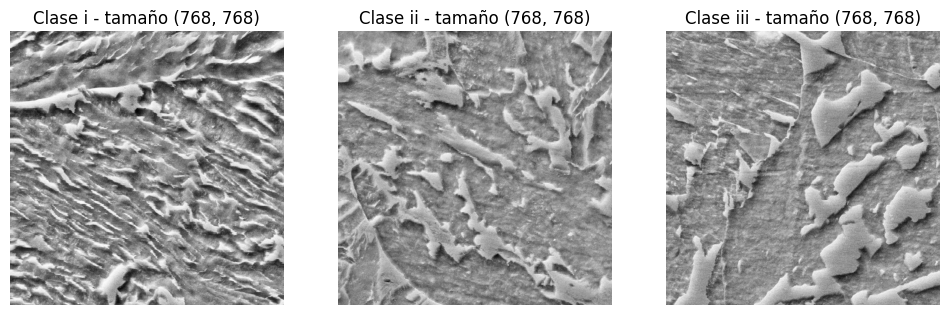

In [ ]:
# Un ejemplo por clase.
plt.figure(figsize=(12, 4))

for i, clase in enumerate(clases):
    carpeta = os.path.join(ruta_train, clase)
    archivo = next(nombre for nombre in os.listdir(carpeta)
                   if nombre.lower().endswith(('.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp')))
    imagen = Image.open(os.path.join(carpeta, archivo)).convert('L')

    plt.subplot(1, 3, i + 1)
    plt.imshow(imagen, cmap='gray')
    plt.title(f'Clase {clase} - tamaño {imagen.size}')
    plt.axis('off')

plt.show()

## 4. Preparar las rutas y las etiquetas

In [ ]:
# Tablay división estratificada de im_train en train/validación.
# testset queda aparte para la evaluación final
extensiones = ('.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp')
etiquetas = {'i': 0, 'ii': 1, 'iii': 2}

def crear_tabla(carpeta):
    datos = []
    for clase in clases:
        carpeta_clase = os.path.join(carpeta, clase)
        for archivo in sorted(os.listdir(carpeta_clase)):
            if archivo.lower().endswith(extensiones):
                datos.append([
                    os.path.join(carpeta_clase, archivo),
                    clase,
                    etiquetas[clase]
                ])
    return pd.DataFrame(datos, columns=['ruta', 'clase', 'label'])

df = crear_tabla(ruta_train)
test_df = crear_tabla(ruta_test)

train_df, val_df = train_test_split(
    df, test_size=0.2, random_state=semilla, stratify=df['label']
)

print('Imágenes de entrenamiento:', len(train_df))
print('Imágenes de validación:', len(val_df))
print('Imágenes de prueba:', len(test_df))

Imágenes de entrenamiento: 745
Imágenes de validación: 187
Imágenes de prueba: 386


## 4.1. Auditoría de fuga de datos (antes del entrenamiento)
Se comparan rutas reales, hashes de archivos, píxeles RGB y píxeles grises, y candidatos por hash perceptual. Coincidencias perceptuales no prueban duplicación; revisar manualmente. Recortes distintos de la misma muestra pueden no coincidir: para descartarlos se necesita un identificador de micrografía/muestra original independiente de la clase. Si existen coincidencias exactas entre particiones, el entrenamiento se bloquea por defecto. No se eliminan imágenes automáticamente, para conservar la comparación.

In [ ]:
particiones = {'train': train_df, 'val': val_df, 'test': test_df}
for (a, ta), (b, tb) in combinations(particiones.items(), 2):
    assert set(map(os.path.realpath, ta.ruta)).isdisjoint(map(os.path.realpath, tb.ruta)), f'Rutas compartidas: {a}/{b}'
print(pd.DataFrame({k: t.clase.value_counts() for k,t in particiones.items()}))
print('Conteos de referencia ViT: 745 / 187 / 386')

def hash_pixeles(im):
    return hashlib.sha256(str(im.size).encode() + im.tobytes()).hexdigest()

def phash(im):
    a = np.asarray(im.resize((32,32), Image.Resampling.LANCZOS), dtype=float)
    co = dctn(a, norm='ortho')[:8,:8].ravel()[1:]
    return int(''.join('1' if x else '0' for x in co > np.median(co)), 2)

registros = []
for nombre, tabla in particiones.items():
    for r in tqdm(tabla.itertuples(index=False), total=len(tabla), desc=nombre):
        with open(r.ruta, 'rb') as f:
            archivo = hashlib.sha256(f.read()).hexdigest()
        with Image.open(r.ruta) as im:
            rgb, gris = im.convert('RGB'), im.convert('L')
            registros.append(dict(split=nombre, ruta=r.ruta, clase=r.clase,
                archivo=archivo, rgb=hash_pixeles(rgb), gris=hash_pixeles(gris),
                phash=phash(gris), ancho=im.width, alto=im.height))
auditoria = pd.DataFrame(registros)
exactos = []
for campo in ['archivo','rgb','gris']:
    for _, g in auditoria.groupby(campo):
        if g.split.nunique() > 1:
            exactos.extend(g.assign(tipo=campo).to_dict('records'))
exactos = pd.DataFrame(exactos, columns=list(auditoria.columns)+['tipo'])
print('Registros de coincidencias exactas entre conjuntos (pueden repetirse):', len(exactos))
display(exactos[['tipo','split','clase','ruta']].head(40))
print('Dimensiones por conjunto y clase:')
display(auditoria.groupby(['split','clase','ancho','alto']).size().rename('cantidad').reset_index())

       train  val  test
clase                  
i        252   64   198
ii       248   62   102
iii      245   61    86
Conteos de referencia ViT: 745 / 187 / 386


train:   0%|          | 0/745 [00:00<?, ?it/s]

val:   0%|          | 0/187 [00:00<?, ?it/s]

test:   0%|          | 0/386 [00:00<?, ?it/s]

Registros de coincidencias exactas entre conjuntos (pueden repetirse): 381


,tipo,split,clase,ruta
0,archivo,train,ii,/content/drive/MyDrive/Colab Notebooks/IA/IA I...
1,archivo,val,ii,/content/drive/MyDrive/Colab Notebooks/IA/IA I...
2,archivo,train,ii,/content/drive/MyDrive/Colab Notebooks/IA/IA I...
3,archivo,val,ii,/content/drive/MyDrive/Colab Notebooks/IA/IA I...
4,archivo,train,iii,/content/drive/MyDrive/Colab Notebooks/IA/IA I...
5,archivo,val,iii,/content/drive/MyDrive/Colab Notebooks/IA/IA I...
6,archivo,train,ii,/content/drive/MyDrive/Colab Notebooks/IA/IA I...
7,archivo,val,ii,/content/drive/MyDrive/Colab Notebooks/IA/IA I...
8,archivo,train,ii,/content/drive/MyDrive/Colab Notebooks/IA/IA I...
9,archivo,val,ii,/content/drive/MyDrive/Colab Notebooks/IA/IA I...


Dimensiones por conjunto y clase:


,split,clase,ancho,alto,cantidad
0,test,i,512,384,198
1,test,ii,512,384,102
2,test,iii,512,384,86
3,train,i,512,512,31
4,train,i,768,768,128
5,train,i,2048,1536,93
6,train,ii,512,512,97
7,train,ii,768,768,62
8,train,ii,2048,1536,89
9,train,iii,512,512,99


Pares candidatos: 74


,split_a,split_b,ruta_a,ruta_b,clase_a,clase_b,distancia
0,train,val,/content/drive/MyDrive/Colab Notebooks/IA/IA I...,/content/drive/MyDrive/Colab Notebooks/IA/IA I...,i,i,0
1,train,val,/content/drive/MyDrive/Colab Notebooks/IA/IA I...,/content/drive/MyDrive/Colab Notebooks/IA/IA I...,i,i,0
2,train,val,/content/drive/MyDrive/Colab Notebooks/IA/IA I...,/content/drive/MyDrive/Colab Notebooks/IA/IA I...,ii,ii,0
3,train,val,/content/drive/MyDrive/Colab Notebooks/IA/IA I...,/content/drive/MyDrive/Colab Notebooks/IA/IA I...,iii,iii,0
4,train,val,/content/drive/MyDrive/Colab Notebooks/IA/IA I...,/content/drive/MyDrive/Colab Notebooks/IA/IA I...,i,i,0
5,train,val,/content/drive/MyDrive/Colab Notebooks/IA/IA I...,/content/drive/MyDrive/Colab Notebooks/IA/IA I...,iii,iii,0
6,train,val,/content/drive/MyDrive/Colab Notebooks/IA/IA I...,/content/drive/MyDrive/Colab Notebooks/IA/IA I...,i,i,0
7,train,val,/content/drive/MyDrive/Colab Notebooks/IA/IA I...,/content/drive/MyDrive/Colab Notebooks/IA/IA I...,i,i,0
8,train,val,/content/drive/MyDrive/Colab Notebooks/IA/IA I...,/content/drive/MyDrive/Colab Notebooks/IA/IA I...,ii,ii,0
9,train,val,/content/drive/MyDrive/Colab Notebooks/IA/IA I...,/content/drive/MyDrive/Colab Notebooks/IA/IA I...,ii,ii,0


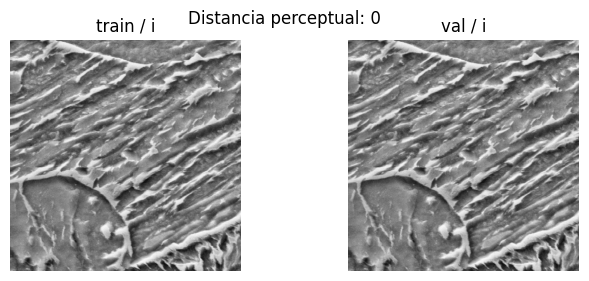

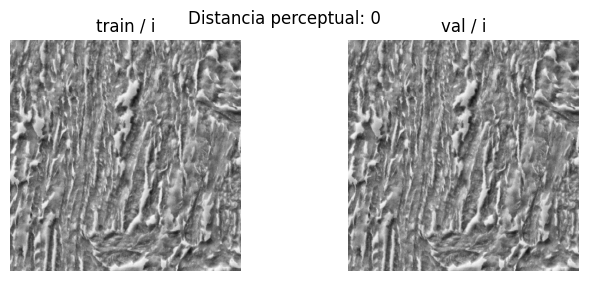

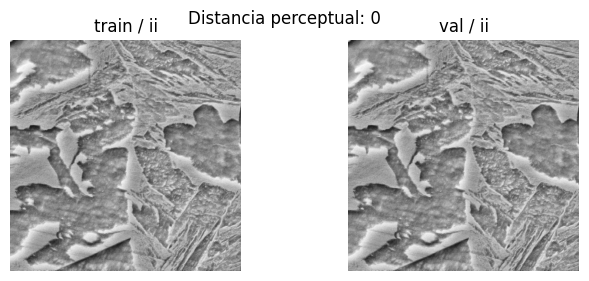

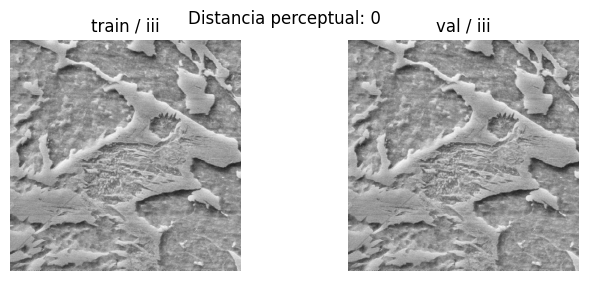

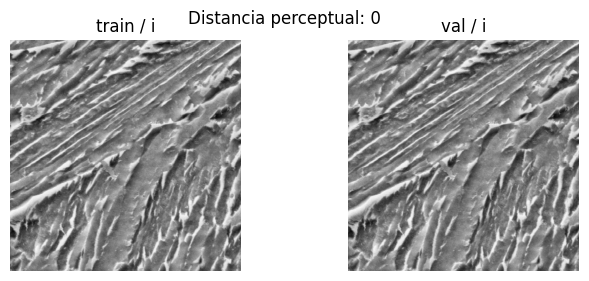

In [ ]:
# Candidatos a duplicados visuales: distancia Hamming <= 5 sobre 63 bits.
# Esta prueba puede dar falsos positivos y negativos; no sustituye la trazabilidad de muestras.
candidatos = []
for a,b in combinations(particiones,2):
    aa = list(auditoria[auditoria.split==a].itertuples(index=False))
    bb = list(auditoria[auditoria.split==b].itertuples(index=False))
    for x in aa:
        for y in bb:
            d = (int(x.phash)^int(y.phash)).bit_count()
            if d <= 5:
                candidatos.append([a,b,x.ruta,y.ruta,x.clase,y.clase,d])
candidatos = pd.DataFrame(candidatos, columns=['split_a','split_b','ruta_a','ruta_b','clase_a','clase_b','distancia'])
candidatos = candidatos.sort_values('distancia')
print('Pares candidatos:',len(candidatos))
display(candidatos.head(20))
for _, r in candidatos.head(5).iterrows():
    fig, ejes = plt.subplots(1,2,figsize=(8,3))
    for ax, p, c, s in zip(ejes,[r.ruta_a,r.ruta_b],[r.clase_a,r.clase_b],[r.split_a,r.split_b]):
        with Image.open(p) as im: ax.imshow(im.convert('L'),cmap='gray')
        ax.set_title(f'{s} / {c}'); ax.axis('off')
    fig.suptitle(f'Distancia perceptual: {r.distancia}'); plt.show()

PERMITIR_DUPLICADOS_PARA_REPRODUCCION = True
if len(exactos) and not PERMITIR_DUPLICADOS_PARA_REPRODUCCION:
    raise RuntimeError('Coincidencias exactas entre conjuntos. Revisar antes de entrenar; cualquier reproducción con ellas no constituye una evaluación independiente.')

In [ ]:
print('========== DATA LEAKAGE ==========')

print('Imágenes por conjunto:')
print(auditoria['split'].value_counts())

print('\nTotal de coincidencias exactas:', len(exactos))

print('Total de coincidencias visuales candidatas:', len(candidatos))

print('\nCoincidencias visuales por conjunto:')
print(candidatos.groupby(['split_a', 'split_b']).size())

========== DATA LEAKAGE ==========
Imágenes por conjunto:
split
train    745
test     386
val      187
Name: count, dtype: int64

Total de coincidencias exactas: 381
Total de coincidencias visuales candidatas: 74

Coincidencias visuales por conjunto:
split_a  split_b
train    val        74
dtype: int64


In [ ]:
import hashlib
from PIL import Image

def hash_pixeles(ruta):
    with Image.open(ruta) as img:
        img = img.convert('RGB')
        return hashlib.sha256(
            str(img.size).encode() + img.tobytes()
        ).hexdigest()

auditoria['hash_verificacion'] = auditoria['ruta'].apply(hash_pixeles)

for a, b in [('train', 'test'), ('train', 'val'), ('val', 'test')]:
    origen = auditoria[auditoria['split'] == a]
    destino = auditoria[auditoria['split'] == b]

    coincidencias = destino['hash_verificacion'].isin(
        origen['hash_verificacion']
    ).sum()

    print(f'{a} vs {b}:')
    print(f'  Imágenes repetidas: {coincidencias}/{len(destino)}')
    print(f'  Porcentaje: {100 * coincidencias / len(destino):.2f}%')

train vs test:
  Imágenes repetidas: 0/386
  Porcentaje: 0.00%
train vs val:
  Imágenes repetidas: 62/187
  Porcentaje: 33.16%
val vs test:
  Imágenes repetidas: 0/386
  Porcentaje: 0.00%


In [ ]:
print('Total de registros:', len(exactos))

print('Total de imágenes únicas involucradas:',
      exactos['ruta'].nunique())

print('\nRegistros por método de detección:')
print(exactos.groupby('tipo').size())

print('\nImágenes únicas duplicadas por conjunto:')
print(exactos.groupby('split')['ruta'].nunique())

Total de registros: 381
Total de imágenes únicas involucradas: 127

Registros por método de detección:
tipo
archivo    127
gris       127
rgb        127
dtype: int64

Imágenes únicas duplicadas por conjunto:
split
train    65
val      62
Name: ruta, dtype: int64


## 5. Preparar las imágenes

In [ ]:
nombre_procesador = 'google/vit-base-patch16-224-in21k'
procesador = ViTImageProcessor.from_pretrained(nombre_procesador)

class DatasetMicrografias(Dataset):
    def __init__(self, tabla, augment=False):
        self.tabla = tabla.reset_index(drop=True)
        self.augment = augment

    def __len__(self):
        return len(self.tabla)

    def __getitem__(self, indice):
        fila = self.tabla.iloc[indice]
        imagen = Image.open(fila['ruta']).convert('L').convert('RGB')

        if self.augment:
            if random.random() < 0.5:
                imagen = imagen.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
            if random.random() < 0.5:
                imagen = imagen.transpose(Image.Transpose.FLIP_TOP_BOTTOM)

        imagen = procesador(images=imagen, return_tensors='pt')['pixel_values'].squeeze(0)
        return imagen, int(fila['label'])

train_ds = DatasetMicrografias(train_df, augment=True)
val_ds = DatasetMicrografias(val_df)
test_ds = DatasetMicrografias(test_df)

lote = 8 if torch.cuda.is_available() else 2
generador = torch.Generator().manual_seed(semilla)   # orden reproducible del barajado
train_loader = DataLoader(train_ds, batch_size=lote, shuffle=True, generator=generador)
val_loader = DataLoader(val_ds, batch_size=lote, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=lote, shuffle=False)

print('Datos preparados.')

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

Datos preparados.


In [ ]:
print('Configuración del procesador compartido:', procesador.to_dict())
print('Lote:', lote)
print('Tensor de ejemplo:', train_ds[0][0].shape)
print('Normalización nativa de ResNet (solo referencia):', ResNet50_Weights.IMAGENET1K_V1.transforms())
# Restablecer RNG: la inspección de train_ds[0] consumió números aleatorios.
random.seed(semilla)


Configuración del procesador compartido: {'do_normalize': True, 'do_resize': True, 'image_mean': (0.5, 0.5, 0.5), 'image_std': (0.5, 0.5, 0.5), 'size': {'height': 224, 'width': 224}, 'resample': <Resampling.BILINEAR: 2>, 'do_rescale': True, 'rescale_factor': 0.00392156862745098, 'image_processor_type': 'ViTImageProcessor'}
Lote: 8
Tensor de ejemplo: torch.Size([3, 224, 224])
Normalización nativa de ResNet (solo referencia): ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


## 6. Crear ResNet50 y ajustar todos los parámetros

In [ ]:
modelo = resnet50(weights=ResNet50_Weights.IMAGENET1K_V1)
modelo.fc = torch.nn.Linear(modelo.fc.in_features, 3)
modelo = modelo.to(dispositivo)
assert all(p.requires_grad for p in modelo.parameters())
print('Parámetros entrenables:', sum(p.numel() for p in modelo.parameters() if p.requires_grad))
pesos = compute_class_weight(class_weight='balanced', classes=np.array([0,1,2]), y=train_df['label'])
pesos = torch.tensor(pesos, dtype=torch.float32).to(dispositivo)
print('Pesos por clase:', pesos)
optimizador = torch.optim.AdamW(modelo.parameters(), lr=2e-5)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:02<00:00, 41.4MB/s]


Parámetros entrenables: 23514179
Pesos por clase: tensor([0.9854, 1.0013, 1.0136], device='cuda:0')


## 7. Entrenar el modelo

In [ ]:
epocas = 10
historial = []
mejor_val_loss = float('inf')
mejor_epoca = None
mejor_pesos = None

for epoca in range(epocas):
    modelo.train()
    perdida_train = 0
    aciertos_train = 0

    for imagenes, etiquetas_lote in tqdm(train_loader, desc=f"Época {epoca+1}/{epocas} - Entrenamiento"):
        imagenes = imagenes.to(dispositivo)
        etiquetas_lote = etiquetas_lote.to(dispositivo)

        optimizador.zero_grad()
        salida = modelo(imagenes)
        perdida = torch.nn.functional.cross_entropy(salida, etiquetas_lote, weight=pesos)
        perdida.backward()
        optimizador.step()

        perdida_train += perdida.item() * len(etiquetas_lote)
        aciertos_train += (salida.argmax(1) == etiquetas_lote).sum().item()

    perdida_train /= len(train_ds)
    acc_train = aciertos_train / len(train_ds)

    # Validación
    modelo.eval()
    perdida_val = 0
    aciertos_val = 0

    with torch.no_grad():
        for imagenes, etiquetas_lote in tqdm(val_loader, desc=f"Época {epoca+1}/{epocas} - Validación"):
            imagenes = imagenes.to(dispositivo)
            etiquetas_lote = etiquetas_lote.to(dispositivo)

            salida = modelo(imagenes)
            perdida = torch.nn.functional.cross_entropy(salida, etiquetas_lote, weight=pesos)

            perdida_val += perdida.item() * len(etiquetas_lote)
            aciertos_val += (salida.argmax(1) == etiquetas_lote).sum().item()

    perdida_val /= len(val_ds)
    acc_val = aciertos_val / len(val_ds)

    historial.append([perdida_train, perdida_val, acc_train, acc_val])

    print(f'Época {epoca+1}/{epocas} - '
          f'loss: {perdida_train:.4f} - acc: {acc_train:.4f} - '
          f'val_loss: {perdida_val:.4f} - val_acc: {acc_val:.4f}')

    if perdida_val < mejor_val_loss:
        mejor_val_loss = perdida_val
        mejor_epoca = epoca + 1
        mejor_pesos = {k: v.cpu().clone() for k, v in modelo.state_dict().items()}

# Recuperar los mejores pesos
modelo.load_state_dict(mejor_pesos)
modelo.to(dispositivo)

historial = np.array(historial)
print(f'\nMejor época: {mejor_epoca} | menor val_loss: {mejor_val_loss:.4f}')

Época 1/10 - Entrenamiento:   0%|          | 0/94 [00:00<?, ?it/s]

Época 1/10 - Validación:   0%|          | 0/24 [00:00<?, ?it/s]

Época 1/10 - loss: 0.6471 - acc: 0.7799 - val_loss: 0.2175 - val_acc: 0.9572


Época 2/10 - Entrenamiento:   0%|          | 0/94 [00:00<?, ?it/s]

Época 2/10 - Validación:   0%|          | 0/24 [00:00<?, ?it/s]

Época 2/10 - loss: 0.2998 - acc: 0.8913 - val_loss: 0.1672 - val_acc: 0.9305


... (20 outputs left out)

Época 9/10 - loss: 0.0840 - acc: 0.9745 - val_loss: 0.0162 - val_acc: 1.0000


Época 10/10 - Entrenamiento:   0%|          | 0/94 [00:00<?, ?it/s]

Época 10/10 - Validación:   0%|          | 0/24 [00:00<?, ?it/s]

Época 10/10 - loss: 0.0593 - acc: 0.9826 - val_loss: 0.0315 - val_acc: 0.9947

Mejor época: 9 | menor val_loss: 0.0162


## 8. Graficar el entrenamiento

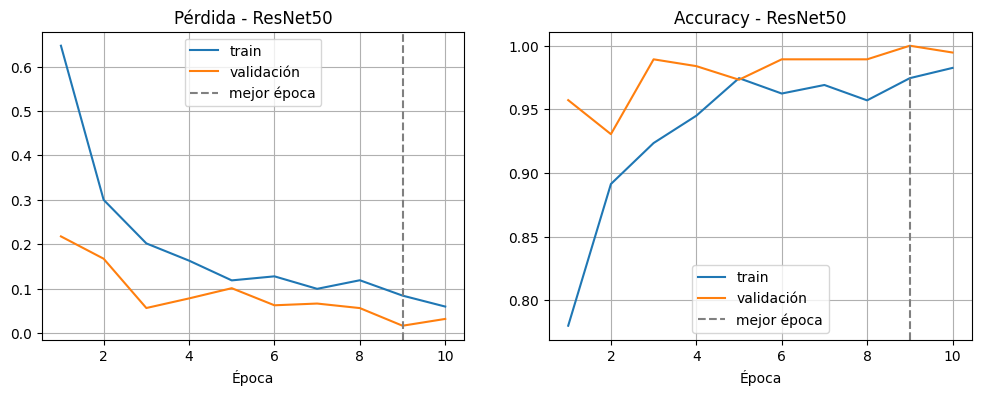

In [ ]:
# Curvas de pérdida y accuracy
eje = range(1, len(historial) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(eje, historial[:, 0], label='train')
plt.plot(eje, historial[:, 1], label='validación')
plt.axvline(mejor_epoca, color='gray', linestyle='--', label='mejor época')
plt.title('Pérdida - ResNet50')
plt.xlabel('Época')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(eje, historial[:, 2], label='train')
plt.plot(eje, historial[:, 3], label='validación')
plt.axvline(mejor_epoca, color='gray', linestyle='--', label='mejor época')
plt.title('Accuracy - ResNet50')
plt.xlabel('Época')
plt.legend()
plt.grid(True)

plt.show()

## 9. Evaluar con el conjunto de prueba

Accuracy en test: 96.37%

              precision    recall  f1-score   support

           i     0.9797    0.9747    0.9772       198
          ii     0.9490    0.9118    0.9300       102
         iii     0.9451    1.0000    0.9718        86

    accuracy                         0.9637       386
   macro avg     0.9579    0.9622    0.9597       386
weighted avg     0.9639    0.9637    0.9635       386



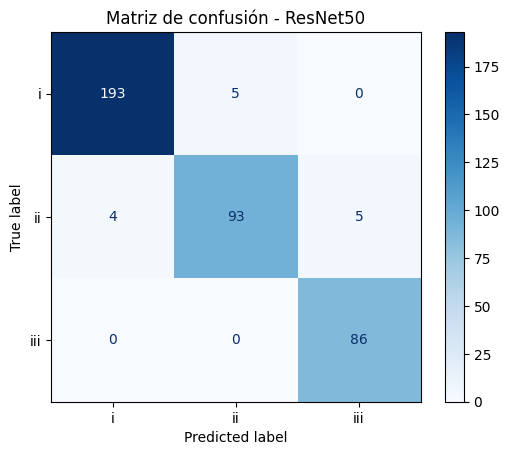

In [ ]:
# Evaluación final sobre testset
# 0 = i, 1 = ii, 2 = iii
modelo.eval()
y_real = []
y_pred = []

with torch.no_grad():
    for imagenes, etiquetas_lote in test_loader:
        imagenes = imagenes.to(dispositivo)
        salida = modelo(imagenes)
        predicciones = salida.argmax(1).cpu().numpy()

        y_real.extend(etiquetas_lote.numpy())
        y_pred.extend(predicciones)

print(f'Accuracy en test: {accuracy_score(y_real, y_pred) * 100:.2f}%\n')
print(classification_report(
    y_real, y_pred, labels=[0, 1, 2], target_names=clases, digits=4, zero_division=0
))

matriz = confusion_matrix(y_real, y_pred, labels=[0, 1, 2])
grafica = ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=clases)
grafica.plot(cmap='Blues', values_format='d')
plt.title('Matriz de confusión - ResNet50')
plt.show()

## 10. Visualización de filtros y activaciones convolucionales

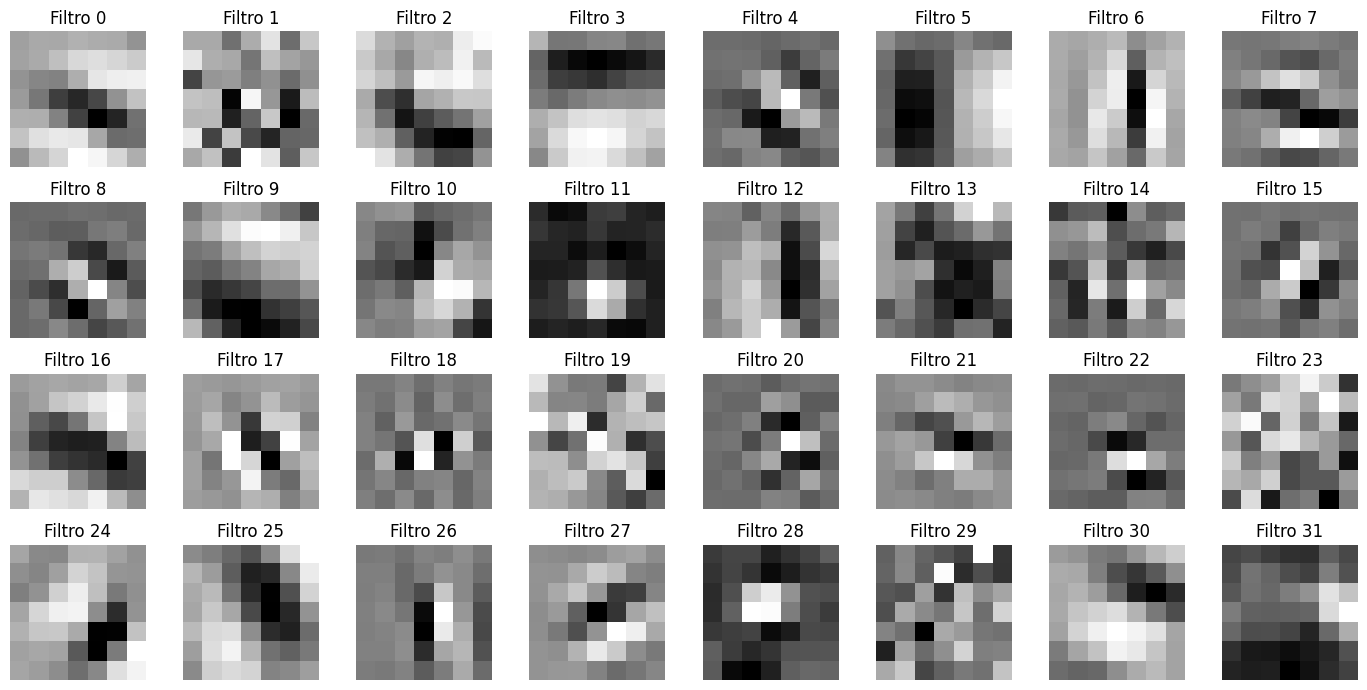

Real: ii | Predicha: ii


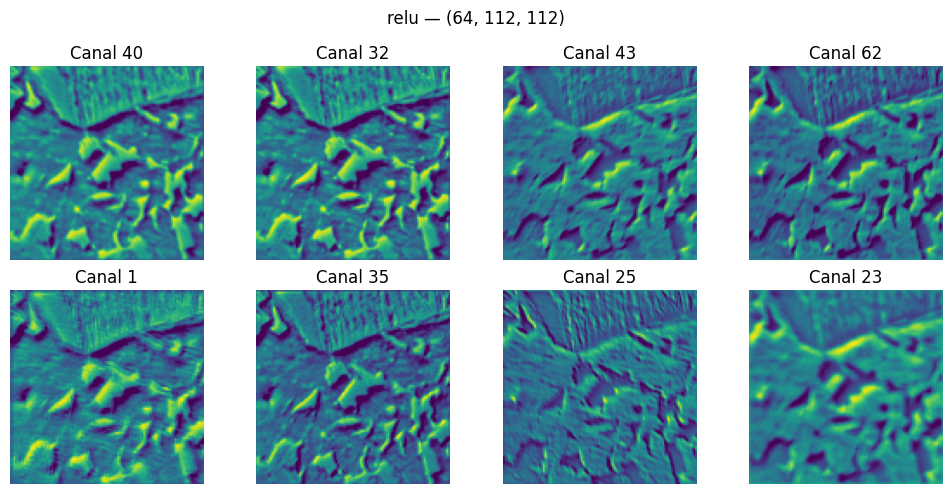

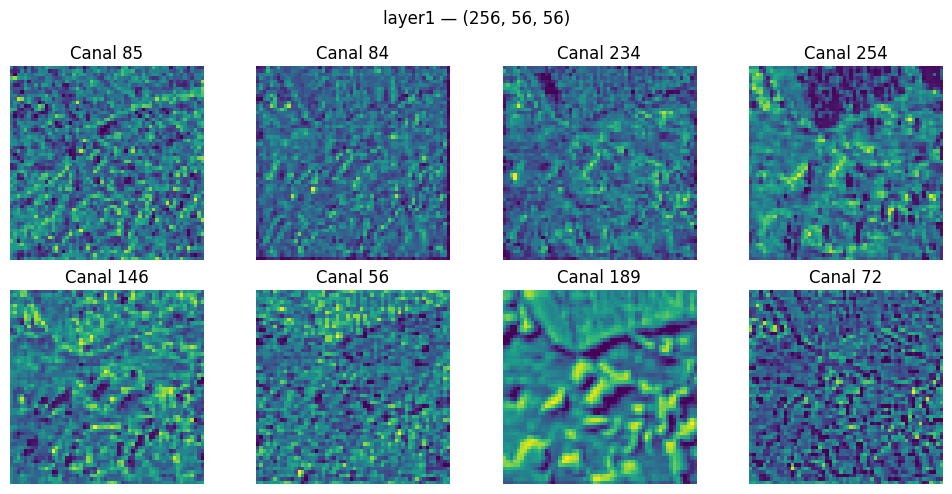

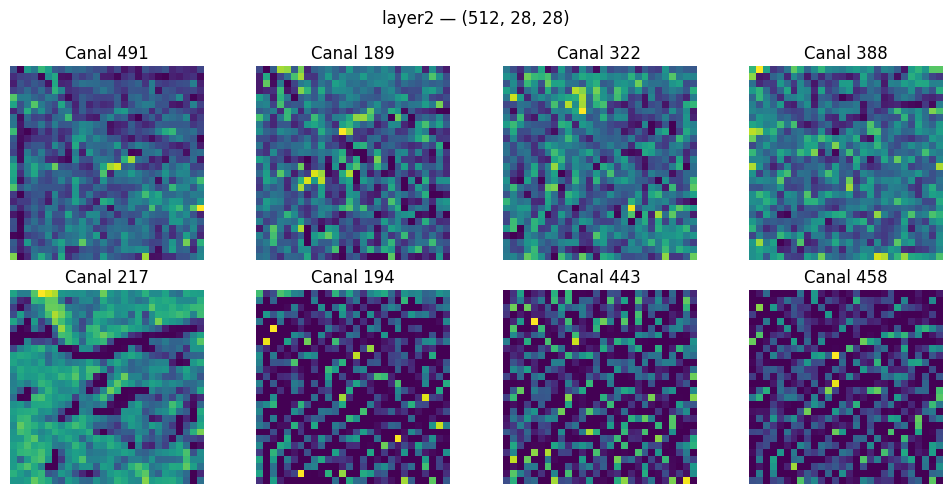

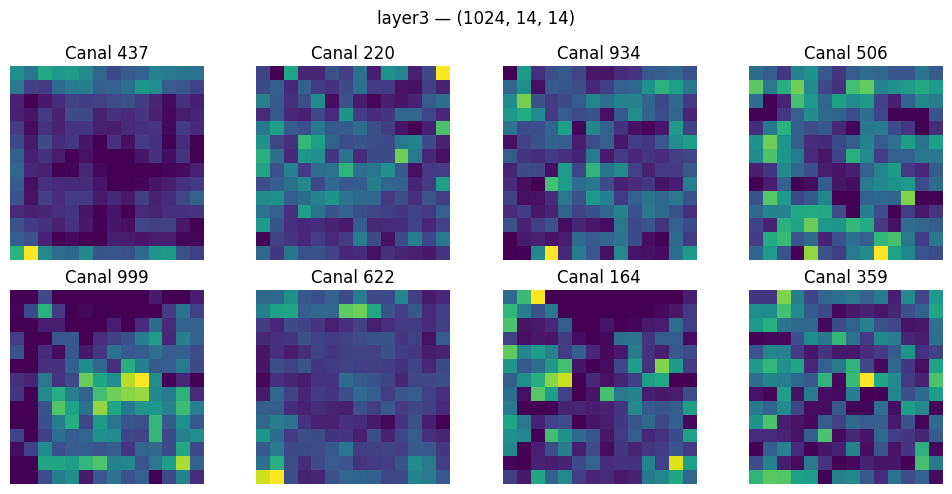

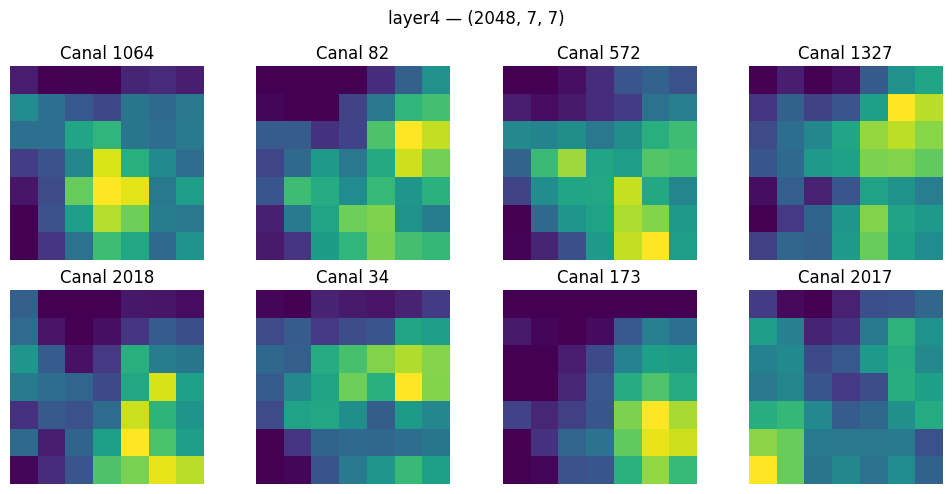

In [ ]:
W = modelo.conv1.weight.detach().cpu().numpy().mean(axis=1)
fig, axs = plt.subplots(4,8,figsize=(14,7))
for i, ax in enumerate(axs.flat):
    ax.imshow(W[i],cmap='gray'); ax.set_title(f'Filtro {i}'); ax.axis('off')
plt.tight_layout(); plt.show()

# Una imagen fija de validación (no de prueba), con el mismo preprocesamiento.
activaciones = {}
def capturar(nombre):
    def hook(mod, inp, out): activaciones[nombre] = out.detach().cpu()[0]
    return hook
capas = ['relu','layer1','layer2','layer3','layer4']
handles = [getattr(modelo,c).register_forward_hook(capturar(c)) for c in capas]
modelo.eval()
entrada, etiqueta = val_ds[0]
try:
    with torch.no_grad(): pred = modelo(entrada.unsqueeze(0).to(dispositivo)).argmax(1).item()
finally:
    for h in handles: h.remove()
print('Real:', clases[etiqueta], '| Predicha:', clases[pred])
for nombre, act in activaciones.items():
    top = act.mean(dim=(1,2)).argsort(descending=True)[:8]
    fig, axs = plt.subplots(2,4,figsize=(10,5))
    for ax,c in zip(axs.flat,top):
        ax.imshow(act[int(c)],cmap='viridis'); ax.set_title(f'Canal {int(c)}'); ax.axis('off')
    fig.suptitle(f'{nombre} — {tuple(act.shape)}'); plt.tight_layout(); plt.show()

## 11. Guardar modelo, predicciones, particiones y auditoría

In [ ]:
from sklearn.metrics import precision_recall_fscore_support
carpeta_modelo = os.path.join(ruta, 'modelo_resnet50_pytorch_comparable')
os.makedirs(carpeta_modelo, exist_ok=True)
torch.save({'state_dict': {k:v.detach().cpu() for k,v in modelo.state_dict().items()},
            'clases': clases, 'arquitectura':'resnet50', 'mejor_epoca':mejor_epoca,
            'preentrenamiento':'IMAGENET1K_V1'}, os.path.join(carpeta_modelo,'modelo.pt'))
procesador.save_pretrained(carpeta_modelo)
pd.DataFrame(historial, columns=['loss_train','loss_val','accuracy_train','accuracy_val']).to_csv(os.path.join(carpeta_modelo,'historial.csv'),index=False)
for nombre, tabla in particiones.items():
    tabla.to_csv(os.path.join(carpeta_modelo,f'{nombre}_manifest.csv'),index=False)
exactos.to_csv(os.path.join(carpeta_modelo,'duplicados_exactos.csv'),index=False)
candidatos.to_csv(os.path.join(carpeta_modelo,'candidatos_perceptuales.csv'),index=False)
resultados = test_df.copy()
resultados['prediccion'] = y_pred
resultados['clase_predicha'] = [clases[i] for i in y_pred]
resultados.to_csv(os.path.join(carpeta_modelo,'predicciones_test.csv'),index=False)
p,r,f,_ = precision_recall_fscore_support(y_real,y_pred,average='macro',zero_division=0)
comparacion = pd.DataFrame([
    {'modelo':'ViT (ejecución original)', 'accuracy':0.9767,'precision_macro':0.9812,'recall_macro':0.9700,'f1_macro':0.9751},
    {'modelo':'ResNet50 Keras (ejecución original)','accuracy':0.6399,'precision_macro':0.7991,'recall_macro':0.6745,'f1_macro':0.6506},
    {'modelo':'ResNet50 PyTorch (esta ejecución)','accuracy':accuracy_score(y_real,y_pred),'precision_macro':p,'recall_macro':r,'f1_macro':f}
])
display(comparacion)
comparacion.to_csv(os.path.join(carpeta_modelo,'comparacion.csv'),index=False)
print('Guardado en:',carpeta_modelo)

,modelo,accuracy,precision_macro,recall_macro,f1_macro
0,ViT (ejecución original),0.976700,0.98120,0.970000,0.975100
1,ResNet50 Keras (ejecución original),0.639900,0.79910,0.674500,0.650600
2,ResNet50 PyTorch (esta ejecución),0.963731,0.95791,0.962171,0.959656


Guardado en: /content/drive/MyDrive/Colab Notebooks/IA/IA II/Proyecto IA2/Bainitic Microstructures/modelo_resnet50_pytorch_comparable


## 12. Interpretación y experimentos posteriores
- La comparación histórica supone que ambas carpetas contienen exactamente las mismas imágenes; los notebooks originales tienen rutas distintas. Los conteos no demuestran identidad.
- Si se confirma que varios recortes pertenecen a la misma micrografía, reconstruir train/val/test por grupos de muestra original, entrenar ambos modelos desde cero y conservar un test independiente. No usar la clase como identificador de grupo.
- Para investigar la franja inferior, comparar imagen completa vs. recorte de primeras 481 filas en ambos modelos, usando validación y el mismo split. La franja podría aportar información espuria (texto, escala, equipo de adquisición), sin que ello demuestre fuga directa.
- Para separar el efecto de normalización, comparar el procesador ViT con la normalización nativa de ResNet usando validación. Para separar el efecto de fine-tuning, comparar base congelada vs. completa, dejando constantes las demás variables.
- Las cifras originales son referencias, no resultados de este notebook. El test histórico ya fue observado; confirmar conclusiones con un conjunto nuevo e independiente. No elegir hiperparámetros por el accuracy de test.
- Repetir con varias semillas y reportar variabilidad; un solo split no demuestra superioridad de una arquitectura.